Dimensiones del dataset: (5572, 2)

Primeras 5 filas:


,etiqueta,mensaje
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Distribución de clases:
etiqueta
ham     4825
spam     747
Name: count, dtype: int64


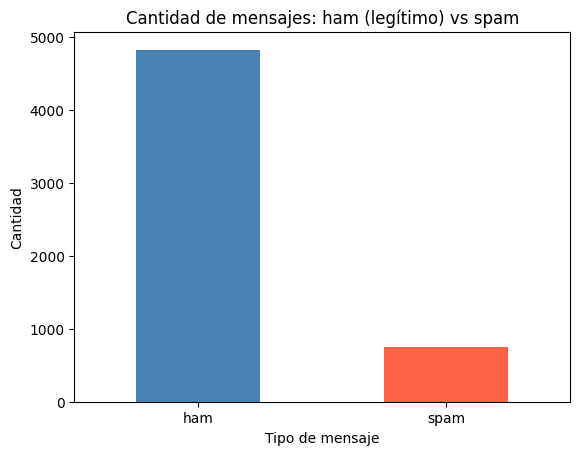

In [4]:
# 1. Importamos las librerías que vamos a usar
import pandas as pd
import matplotlib.pyplot as plt

# 2. Leemos el archivo. El encoding "latin-1" evita errores con caracteres raros
df = pd.read_csv("/content/spam.csv", encoding="latin-1")

# 3. Nos quedamos solo con las 2 columnas útiles y les ponemos nombres claros
df = df[["v1", "v2"]]
df.columns = ["etiqueta", "mensaje"]

# 4. Primer vistazo a los datos
print("Dimensiones del dataset:", df.shape)
print("\nPrimeras 5 filas:")
display(df.head())
print("\nDistribución de clases:")
print(df["etiqueta"].value_counts())

# 5. Gráfico de la distribución
df["etiqueta"].value_counts().plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Cantidad de mensajes: ham (legítimo) vs spam")
plt.xlabel("Tipo de mensaje")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.show()

Precisión general: 0.9686
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



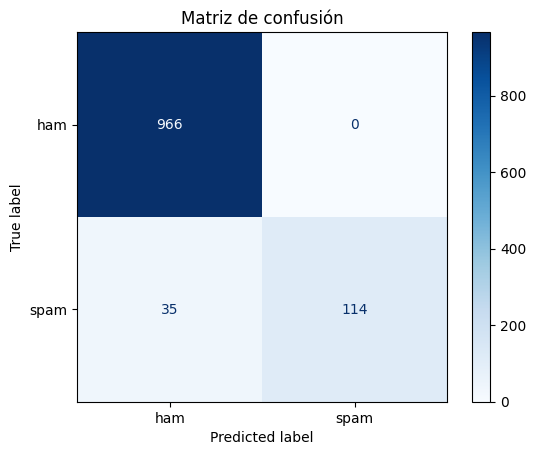

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Convertimos las etiquetas a números
df["y"] = df["etiqueta"].map({"ham": 0, "spam": 1})

# 2. Separamos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    df["mensaje"], df["y"], test_size=0.2, random_state=42, stratify=df["y"]
)

# 3. Convertimos el texto en números con TF-IDF
vectorizador = TfidfVectorizer(lowercase=True, stop_words="english")
X_train_vec = vectorizador.fit_transform(X_train)  # aprende el vocabulario solo con train
X_test_vec = vectorizador.transform(X_test)

# 4. Entrenamos el modelo Naive Bayes
modelo = MultinomialNB()
modelo.fit(X_train_vec, y_train)

# 5. Evaluamos con los datos que el modelo nunca vio
y_pred = modelo.predict(X_test_vec)
print("Precisión general:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

# 6. Matriz de confusión
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["ham", "spam"]).plot(cmap="Blues")
plt.title("Matriz de confusión")
plt.show()

Precisión general: 0.9821
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.94      0.92      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



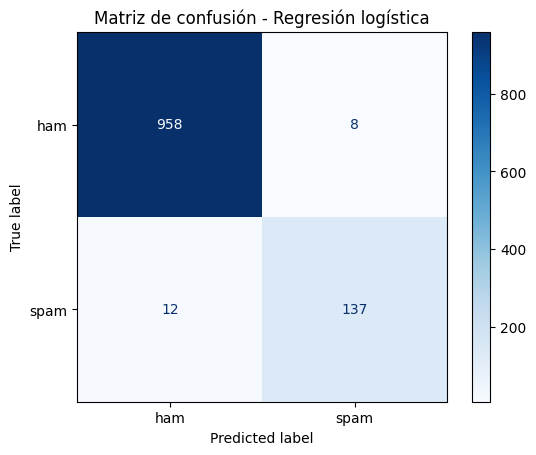

Predicción para ejemplos: [1 0 1]


In [6]:
from sklearn.linear_model import LogisticRegression

# class_weight="balanced" le da más importancia a la clase minoritaria (spam)
modelo2 = LogisticRegression(class_weight="balanced", max_iter=1000)
modelo2.fit(X_train_vec, y_train)

y_pred2 = modelo2.predict(X_test_vec)
print("Precisión general:", round(accuracy_score(y_test, y_pred2), 4))
print(classification_report(y_test, y_pred2, target_names=["ham", "spam"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred2), display_labels=["ham", "spam"]).plot(cmap="Blues")
plt.title("Matriz de confusión - Regresión logística")
plt.show()

# Probamos con mensajes propios (el dataset está en inglés, así que van en inglés)
ejemplos = [
    "Congratulations! You won a free prize. Click here to claim now",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT! Your account has been selected for a cash reward. Call now"
]
print("Predicción para ejemplos:", modelo2.predict(vectorizador.transform(ejemplos)))  # 0 = ham, 1 = spam